In [16]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.linalg import eigh,cho_factor,cho_solve

In [ ]:
# -------------------- Example settings --------------------
example_name = "Example2"

kappa,m = 0.2,2
L,N,dt,T = np.pi,1200,5e-5,0.5
theta,Ct = 2.0,1

p = dict(M=80,ell_V=0.5,ell_W=0.7,
         lam_V=1e-8,lam_W=1e-7,rank_tol=1e-13)

# p = dict(M=80,ell_V=0.5,ell_W=0.7,
#         lam_V=1e-7,lam_W=1e-6,rank_tol=1e-13)

# p = dict(M=80,ell_V=0.5,ell_W=0.7,
#         lam_V=1e-9,lam_W=1e-8,rank_tol=1e-13)

def V(x):
    return np.sin(2*x)

def W(r):
    return np.cos(2*r)+np.cos(r)

def rho0(x):
    return (1+0.5*np.cos(2*x))/(2*np.pi)

def Uprime(r):
    return kappa*r**(m-1)

root = Path(example_name)
data_dir,fig_dir = root/"data",root/"figures"
for folder in (data_dir,fig_dir):
    folder.mkdir(parents=True,exist_ok=True)

def savefig(fig,name):
    for ext in ("png","pdf"):
        fig.savefig(fig_dir/f"{example_name}_{name}.{ext}", dpi=300,bbox_inches="tight")

Example: Example2; data shape: (10001, 1200)
Maximum mass error: 5.551e-16
Maximum stage CFL ratio: 0.0395
Minimum saved density: 4.534900e-02
k= 1: excitation=7.438546e-16
k= 2: excitation=5.897324e-01
k= 3: excitation=7.634754e-16
k= 4: excitation=3.056245e-01
k= 5: excitation=6.331147e-16
k= 6: excitation=1.545927e-01
k= 7: excitation=4.954390e-16
k= 8: excitation=6.616741e-02
k= 9: excitation=3.718666e-16
k=10: excitation=2.164082e-02
k=11: excitation=2.205492e-16
k=12: excitation=7.816121e-03
k=13: excitation=4.128788e-16
k=14: excitation=6.975472e-03
k=15: excitation=3.262941e-16
k=16: excitation=4.499419e-03
k=17: excitation=3.931245e-16
k=18: excitation=2.139708e-03
k=19: excitation=3.536326e-16
k=20: excitation=1.273334e-03


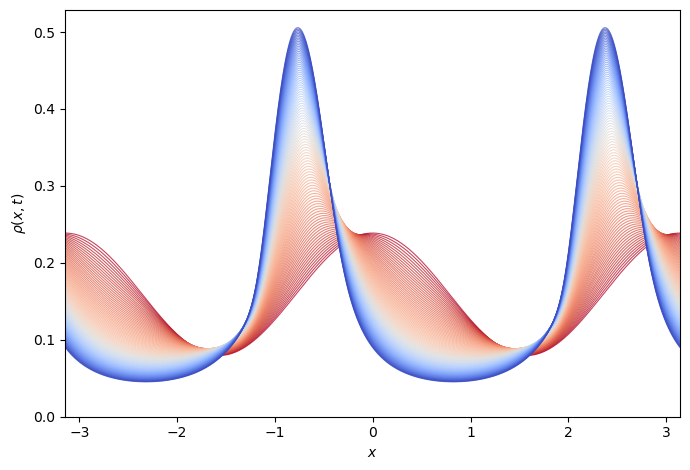

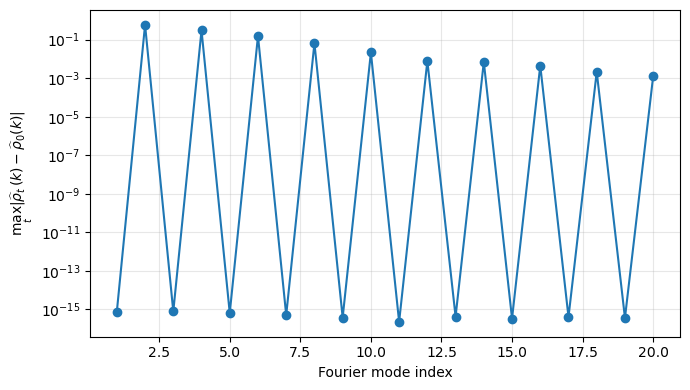

In [18]:
# Periodic finite-volume scheme + minmod reconstruction + SSP-RK3.
# Normalize rho0 to unit mass; remove potential constants to fix the gauge.

dx,num_steps = 2*L/N,int(round(T/dt))
assert N>=8 and dt>0 and T>0 and Ct>=1 and 1<=theta<=2
assert np.isclose(num_steps*dt,T)
x = -L+(np.arange(N)+0.5)*dx
lags = np.arange(N)*dx

V_values = np.asarray(V(x),dtype=float)
W_values = np.asarray(W(lags),dtype=float)
assert V_values.shape==W_values.shape==(N,)
assert np.isfinite(V_values).all() and np.isfinite(W_values).all()
V_values -= V_values.mean()
W_values -= W_values.mean()
W_fft = np.fft.fft(W_values)

def conv_W_rho(r):
    return dx*np.fft.ifft(W_fft*np.fft.fft(r)).real

def minmod3(a,b,c):
    out = np.zeros_like(a)
    pos,neg = (a>0)&(b>0)&(c>0),(a<0)&(b<0)&(c<0)
    out[pos] = np.minimum(np.minimum(a[pos],b[pos]),c[pos])
    out[neg] = np.maximum(np.maximum(a[neg],b[neg]),c[neg])
    return out

def velocity(r):
    xi = Uprime(r)+V_values+conv_W_rho(r)
    return -(np.roll(xi,-1)-xi)/dx

def rhs(r,u):
    jm,jp = np.roll(r,1),np.roll(r,-1)
    slope = minmod3(theta*(r-jm)/dx,(jp-jm)/(2*dx),theta*(jp-r)/dx)
    rW,rE = r-0.5*dx*slope,r+0.5*dx*slope
    flux = np.maximum(u,0)*rE+np.minimum(u,0)*np.roll(rW,-1)
    return -(flux-np.roll(flux,1))/dx

max_cfl_ratio = 0.0
def euler(r):
    global max_cfl_ratio
    if not np.isfinite(r).all() or r.min()<0:
        raise RuntimeError("Invalid RK stage density")
    u = velocity(r)
    ratio = 2*dt*np.max(np.abs(u))/dx
    if not np.isfinite(ratio) or ratio>1:
        raise RuntimeError(f"CFL violated: ratio={ratio:.6e}")
    max_cfl_ratio = max(max_cfl_ratio,ratio)
    out = r+dt*rhs(r,u)
    if not np.isfinite(out).all() or out.min()<0:
        raise RuntimeError("Invalid Euler output")
    return out

def ssprk3_step(r):
    r1 = euler(r)
    r2 = 0.75*r+0.25*euler(r1)
    return r/3+2*euler(r2)/3

rho = np.asarray(rho0(x),dtype=float)
assert rho.shape==(N,) and np.isfinite(rho).all() and rho.min()>=0
assert rho.sum()>0
rho /= dx*rho.sum()
mass0 = dx*rho.sum()
times,snapshots = [],[]

for n in range(num_steps+1):
    if n%Ct==0 or n==num_steps:
        times.append(n*dt)
        snapshots.append(rho.copy())
    if n==num_steps: break
    rho = ssprk3_step(rho)

times,snapshots = np.asarray(times),np.asarray(snapshots)
mass = dx*snapshots.sum(axis=1)
modes = np.arange(1,min(20,(N-1)//2)+1)
wave = np.pi*modes/L
fourier = dx*snapshots@np.exp(-1j*np.outer(x,wave))
excitation = np.max(np.abs(fourier-fourier[0]),axis=0)

print(f"Example: {example_name}; data shape: {snapshots.shape}")
print(f"Maximum mass error: {np.max(np.abs(mass-mass0)):.3e}")
print(f"Maximum stage CFL ratio: {max_cfl_ratio:.4f}")
print(f"Minimum saved density: {snapshots.min():.6e}")
for k,q in zip(modes,excitation):
    print(f"k={k:2d}: excitation={q:.6e}")

np.savez(data_dir/"trajectory.npz",x=x,t=times,rho=snapshots,
         V=V_values,W_lags=W_values,lags=lags,L=L,N=N,
         m=m,kappa=kappa,dx=dx,dt=dt,Ct=Ct,
         Uprime_rho=Uprime(snapshots),
         modes=modes,fourier=fourier,excitation=excitation)

fig,ax = plt.subplots(figsize=(7,4.8))
idx = np.unique(np.linspace(0,len(times)-1,101,dtype=int))
for i,c in zip(idx,plt.cm.coolwarm_r(np.linspace(0,1,len(idx)))):
    ax.plot(x,snapshots[i],color=c,lw=0.8,alpha=0.75)
ax.set(xlim=(-L,L),ylim=(0,None),xlabel=r"$x$",ylabel=r"$\rho(x,t)$")
fig.tight_layout()
savefig(fig,"density_evolution")
plt.show()

fig,ax = plt.subplots(figsize=(7,4))
ax.semilogy(modes,np.maximum(excitation,1e-16),"o-")
ax.set(xlabel="Fourier mode index",
       ylabel=r"$\max_t|\widehat\rho_t(k)-\widehat\rho_0(k)|$")
ax.grid(True,alpha=0.3)
fig.tight_layout()
savefig(fig,"fourier_excitation")
plt.show()

Processed 2000/10000 training intervals
Processed 4000/10000 training intervals
Processed 6000/10000 training intervals
Processed 8000/10000 training intervals
Processed 10000/10000 training intervals
Checked 2000/10000 residual intervals
Checked 4000/10000 residual intervals
Checked 6000/10000 residual intervals
Checked 8000/10000 residual intervals
Checked 10000/10000 residual intervals
Kernel dimensions: V=30, W=22
cond(H): 4.660e+07
Truth Adelta residual:          2.732671e-04
Estimated Adelta residual:      2.551356e-04
Alternative Adelta residual:    2.551356e-04
Maximum |cos*rho|:              4.355e-16
Maximum |(cos)'*rho|:           3.951e-16
V relative L2 error:            1.6578e-04
V' relative L2 error:           1.7147e-04
W error, full truth:           7.0711e-01
W' error, full truth:          4.4721e-01
W error, representative:       4.0583e-04
W error, after adding cos(x):  2.8697e-04
W' error, after adding cos(x): 4.8563e-04


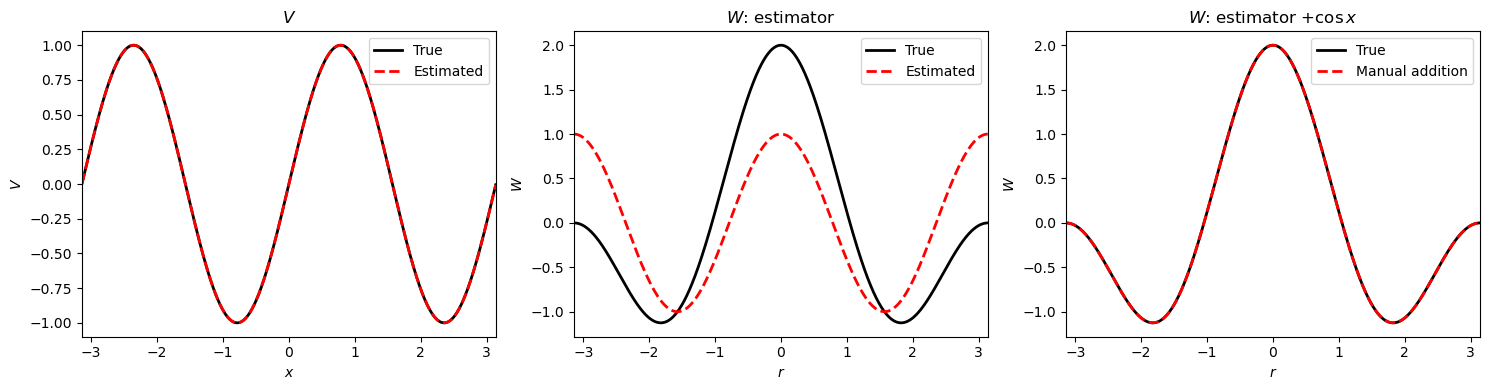

In [19]:
# Periodic Gaussian RKHS; no evenness constraint on W.
# Central spatial differences, forward time differences, every saved interval.
# Saved truth is used only for diagnostics and evaluation.
# Example 2: manually add cos(x) after learning to illustrate ambiguity.

data = np.load(data_dir/"trajectory.npz")
x,t,rho = data["x"],data["t"],data["rho"]
U_data = data["Uprime_rho"]
L = float(data["L"])
N,dx = len(x),x[1]-x[0]
assert len(t)>=2 and rho.shape==U_data.shape==(len(t),N)
assert np.isfinite(rho).all() and rho.min()>=0
assert np.allclose(np.diff(x),dx) and np.all(np.diff(t)>0)
assert np.isclose(L,np.pi), "This example uses the invisible component cos(x)."

def kernel(x,z,ell,deriv=0):
    period = 2*L
    q = (np.asarray(x)[:,None]-np.asarray(z)[None,:]+L)%period-L
    J = int(np.ceil((L+9*ell)/period))
    out = np.zeros_like(q)
    for j in range(-J,J+1):
        r = q+period*j
        g = np.exp(-r*r/(2*ell*ell))
        if deriv==0: out += g
        elif deriv==1: out += -r*g/ell**2
        elif deriv==2: out += (r*r/ell**4-1/ell**2)*g
        else: raise ValueError("deriv must be 0, 1 or 2")
    return out if deriv else out-np.sqrt(2*np.pi)*ell/period

def whiten(z,ell):
    G = kernel(z,z,ell)
    s,U = eigh((G+G.T)/2)
    keep = s>p["rank_tol"]*s.max()
    return U[:,keep]/np.sqrt(s[keep])

def Dx(u):
    return (np.roll(u,-1)-np.roll(u,1))/(2*dx)

def Dxx(u):
    return (np.roll(u,-1)-2*u+np.roll(u,1))/dx**2

def relerr(a,b):
    return np.linalg.norm(a-b)/max(np.linalg.norm(b),1e-14)

freq = 2*np.pi*np.fft.fftfreq(N,d=dx)

def spectral_derivative(u,order):
    return np.fft.ifft((1j*freq)**order*np.fft.fft(u)).real

zV = np.linspace(-L,L,p["M"],endpoint=False)
zW = np.linspace(-L,L,p["M"],endpoint=False)
QV,QW = whiten(zV,p["ell_V"]),whiten(zW,p["ell_W"])
BV1 = kernel(x,zV,p["ell_V"],1)@QV
BV2 = kernel(x,zV,p["ell_V"],2)@QV

lags = data["lags"]
DW1 = kernel(lags,zW,p["ell_W"],1)@QW
DW2 = kernel(lags,zW,p["ell_W"],2)@QW
FW = np.fft.fft(np.hstack((DW1,DW2)),axis=0)
nV,nW = QV.shape[1],QW.shape[1]
A,b,y2 = np.zeros((nV+nW,nV+nW)),np.zeros(nV+nW),0.0

def observation_block(l):
    r,U = rho[l],U_data[l]
    h = t[l+1]-t[l]
    rx = Dx(r)
    y = (rho[l+1]-r)/h-rx*Dx(U)-r*Dxx(U)
    C = dx*np.fft.ifft(FW*np.fft.fft(r)[:,None],axis=0).real
    B = np.hstack((rx[:,None]*BV1+r[:,None]*BV2,
                   rx[:,None]*C[:,:nW]+r[:,None]*C[:,nW:]))
    return B,y,r*dx*h,rx

# Truth diagnostics do not enter the training matrices A and b.
Vref = data["V"]
VP,VPP = spectral_derivative(Vref,1),spectral_derivative(Vref,2)
Wlags = data["W_lags"]
FT = np.fft.fft(np.column_stack((
    spectral_derivative(Wlags,1),spectral_derivative(Wlags,2))),axis=0)
truth_err2 = 0.0

for l in range(len(t)-1):
    B,y,w,rx = observation_block(l)
    A += B.T@(w[:,None]*B)
    b += B.T@(w*y)
    y2 += np.dot(w*y,y)

    C = dx*np.fft.ifft(FT*np.fft.fft(rho[l])[:,None],axis=0).real
    truth_A = rx*(VP+C[:,0])+rho[l]*(VPP+C[:,1])
    e = truth_A-y
    truth_err2 += np.dot(w*e,e)

    if (l+1)%2000==0:
        print(f"Processed {l+1}/{len(t)-1} training intervals")

A = (A+A.T)/2
reg = np.r_[np.full(nV,p["lam_V"]),np.full(nW,p["lam_W"])]
H = A+np.diag(reg)
c = cho_solve(cho_factor(H,lower=True),b)
cV,cW = QV@c[:nV],QW@c[nV:]
truth_residual = np.sqrt(truth_err2/max(y2,1e-28))

Vhat = kernel(x,zV,p["ell_V"])@cV
What = kernel(x,zW,p["ell_W"])@cW
Vphat = kernel(x,zV,p["ell_V"],1)@cV
Wphat = kernel(x,zW,p["ell_W"],1)@cW

# Shift the saved lag-grid truth onto x.
phase = np.exp(1j*freq*(x[0]-lags[0]))
Wref = np.fft.ifft(np.fft.fft(Wlags)*phase).real
Wpref = spectral_derivative(Wref,1)

# Manual addition after solving: this component is not learned.
psi,psip = np.cos(x),-np.sin(x)
Walternative = What+psi
Wpalternative = Wphat+psip

# Direct residual comparison for (Vhat, What) and (Vhat, What+cos x).
Fpsi = np.fft.fft(np.column_stack((
    np.cos(lags),-np.sin(lags),-np.cos(lags))),axis=0)
err2,alternative_err2,invisible_error,force_error = 0.0,0.0,0.0,0.0

for l in range(len(t)-1):
    B,y,w,rx = observation_block(l)
    e = B@c-y
    C = dx*np.fft.ifft(Fpsi*np.fft.fft(rho[l])[:,None],axis=0).real
    extra_A = rx*C[:,1]+rho[l]*C[:,2]
    err2 += np.dot(w*e,e)
    alternative_err2 += np.dot(w*(e+extra_A),e+extra_A)
    invisible_error = max(invisible_error,np.max(np.abs(C[:,0])))
    force_error = max(force_error,np.max(np.abs(C[:,1])))

    if (l+1)%2000==0:
        print(f"Checked {l+1}/{len(t)-1} residual intervals")

residual = np.sqrt(err2/max(y2,1e-28))
alternative_residual = np.sqrt(alternative_err2/max(y2,1e-28))

print(f"Kernel dimensions: V={nV}, W={nW}")
print(f"cond(H): {np.linalg.cond(H):.3e}")
print(f"Truth Adelta residual:          {truth_residual:.6e}")
print(f"Estimated Adelta residual:      {residual:.6e}")
print(f"Alternative Adelta residual:    {alternative_residual:.6e}")
print(f"Maximum |cos*rho|:              {invisible_error:.3e}")
print(f"Maximum |(cos)'*rho|:           {force_error:.3e}")
print(f"V relative L2 error:            {relerr(Vhat,Vref):.4e}")
print(f"V' relative L2 error:           {relerr(Vphat,VP):.4e}")
print(f"W error, full truth:           {relerr(What,Wref):.4e}")
print(f"W' error, full truth:          {relerr(Wphat,Wpref):.4e}")
print(f"W error, representative:       {relerr(What,Wref-psi):.4e}")
print(f"W error, after adding cos(x):  {relerr(Walternative,Wref):.4e}")
print(f"W' error, after adding cos(x): {relerr(Wpalternative,Wpref):.4e}")

fig,axs = plt.subplots(1,3,figsize=(15,4))
plots = [
    (Vref,Vhat,"V",r"$V$"),
    (Wref,What,"W",r"$W$: estimator"),
    (Wref,Walternative,"W",r"$W$: estimator $+\cos x$")
]
for i,(truth,estimate,name,title) in enumerate(plots):
    ax = axs[i]
    ax.plot(x,truth,"k-",lw=2,label="True")
    ax.plot(x,estimate,"r--",lw=2,
            label="Manual addition" if i==2 else "Estimated")
    ax.set(xlabel=r"$x$" if name=="V" else r"$r$",
           ylabel=f"${name}$",title=title,xlim=(-L,L))
    ax.legend()
fig.tight_layout()
savefig(fig,"reconstruction")
plt.show()

np.savez(data_dir/"reconstruction.npz",x=x,V_hat=Vhat,W_hat=What,
         Vp_hat=Vphat,Wp_hat=Wphat,W_alternative=Walternative,
         Wp_alternative=Wpalternative,psi=psi,
         zV=zV,zW=zW,cV=cV,cW=cW,
         residual=residual,truth_residual=truth_residual,
         alternative_residual=alternative_residual,
         invisible_error=invisible_error,force_error=force_error,
         spatial_scheme="periodic central",**p)